In [1]:
import sys
from pathlib import Path

_root = next(p for p in Path.cwd().resolve().parents if (p / '.git').exists() or (p / 'setup.py').exists())
for _p in (str(_root), str(_root / 'src')):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import numpy as np
import scanpy as sc
from metab_processing.metab_travlr_config import DATA_DIR
from metab_processing.LinearRegression import signature_helpers as sh


DATASET = 'FFPE_Human_Breast_Cancer'
ADATA_PATH = f'{DATA_DIR}/Atera/{DATASET}/LinearRegression/hvgall_x_adata.h5ad'
CELL_TYPE_COL = 'cell_type'
T_CELL_TYPES = [
    'T Lymphocytes',
]

METHOD, PENALTY, STANDARDIZE = 'l1', 0.005, True
N_SUB = 50
LOWER, UPPER = 15, 85
DBVER = '2024.1.Hs'

# T-cell program signatures we PREDICT (as pseudo-gene targets).
TCELL_TARGETS = [
    'HALLMARK_IL2_STAT5_SIGNALING',
    'KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY',
    'GOBP_T_CELL_MEDIATED_CYTOTOXICITY',
    'KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY',
    'HALLMARK_TNFA_SIGNALING_VIA_NFKB',
    'HALLMARK_INTERFERON_GAMMA_RESPONSE',
    'HALLMARK_INTERFERON_ALPHA_RESPONSE',
    'GOBP_CELL_KILLING',
    'GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY',
    'GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY',
]
NEG_CONTROL = [
    'HALLMARK_PANCREAS_BETA_CELLS',
    'HALLMARK_SPERMATOGENESIS',
]

# Cancer-associated signatures we ADD AS FACTORS (spatial-neighborhood predictors),
# split by cell type. PECAM1 (= CD31) is a one-gene vessel marker, its own set.
CANCER_FACTORS = [
    'HALLMARK_ESTROGEN_RESPONSE_EARLY',
    'HALLMARK_ESTROGEN_RESPONSE_LATE',
    'WP_BREAST_CANCER_PATHWAY',
    'HALLMARK_G2M_CHECKPOINT',
    'HALLMARK_E2F_TARGETS',
    'HALLMARK_ANGIOGENESIS',
    'HALLMARK_P53_PATHWAY',
    'HALLMARK_KRAS_SIGNALING_UP',
    'HALLMARK_KRAS_SIGNALING_DN',
    'HALLMARK_MYC_TARGETS_V1',
    'HALLMARK_GLYCOLYSIS',
    'HALLMARK_HYPOXIA',
    'HALLMARK_OXIDATIVE_PHOSPHORYLATION',
    'HALLMARK_CHOLESTEROL_HOMEOSTASIS',
    'HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY',
    'KEGG_GLYCOLYSIS_GLUCONEOGENESIS',
    'KEGG_PENTOSE_PHOSPHATE_PATHWAY',
    'KEGG_CITRATE_CYCLE_TCA_CYCLE',
    'KEGG_ONE_CARBON_POOL_BY_FOLATE',
    'KEGG_PURINE_METABOLISM',
]
VESSEL = {'VESSEL_PECAM1': ['PECAM1']}

In [2]:
adata = sc.read_h5ad(ADATA_PATH)
var = set(adata.var_names)
print(adata.n_obs, 'cells |', len(adata.uns.get('x_genes', [])), 'built genes')
print('\ncell_type value counts:')
print(adata.obs[CELL_TYPE_COL].value_counts())

170045 cells | 18028 built genes

cell_type value counts:
cell_type
11q13 High Grade DCIS Cells                 64036
CAFs, Low Grade DCIS Associated             24442
Luminal-like Amorphous DCIS Cells           13028
Basal-like Structured DCIS Cells             8760
Endothelial Cells                            8624
Myoepithelial Cells                          8438
Pericytes                                    8087
T Lymphocytes                                8018
CXCL14+ Fibroblasts                          4936
Dendritic Cells                              4008
CAFs, High Grade DCIS Associated             4001
Macrophages                                  3861
Plasma & Mast Cell Mixture                   2512
11q13 High Grade DCIS Cells (Mitotic)        2462
11q13 High Grade DCIS Tumor Cells (G1/S)     2374
Plasma Cells                                  873
Myeloid Cells                                 813
Apocrine Cells                                403
Mast Cells                      

In [3]:
library = sh.load_msigdb(DBVER)
print('loaded', len(library), 'gene sets')

loaded 10410 gene sets


## T-cell TARGET signatures: membership, missing, present, factor-removed, remaining

In [4]:
tcell_sets = sh.resolve_sets(TCELL_TARGETS + NEG_CONTROL, library, var,
                           label='T-cell targets + negative controls')
sh.report_factor_removal(adata, tcell_sets)

===== T-cell targets + negative controls: membership vs data (12 sets) =====

HALLMARK_IL2_STAT5_SIGNALING  (199/199 present)
  in signature (199): ['ABCB1', 'ADAM19', 'AGER', 'AHCY', 'AHNAK', 'AHR', 'ALCAM', 'AMACR', 'ANXA4', 'APLP1', 'ARL4A', 'BATF', 'BATF3', 'BCL2', 'BCL2L1', 'BHLHE40', 'BMP2', 'BMPR2', 'CA2', 'CAPG', 'CAPN3', 'CASP3', 'CCND2', 'CCND3', 'CCNE1', 'CCR4', 'CD44', 'CD48', 'CD79B', 'CD81', 'CD83', 'CD86', 'CDC42SE2', 'CDC6', 'CDCP1', 'CDKN1C', 'CISH', 'CKAP4', 'COCH', 'COL6A1', 'CSF1', 'CSF2', 'CST7', 'CTLA4', 'CTSZ', 'CXCL10', 'CYFIP1', 'DCPS', 'DENND5A', 'DHRS3', 'DRC1', 'ECM1', 'EEF1AKMT1', 'EMP1', 'ENO3', 'ENPP1', 'EOMES', 'ETFBKMT', 'ETV4', 'F2RL2', 'FAH', 'FGL2', 'FLT3LG', 'FURIN', 'GABARAPL1', 'GADD45B', 'GALM', 'GATA1', 'GBP4', 'GLIPR2', 'GPR65', 'GPR83', 'GPX4', 'GSTO1', 'GUCY1B1', 'HIPK2', 'HK2', 'HOPX', 'HUWE1', 'HYCC2', 'ICOS', 'IFITM3', 'IFNGR1', 'IGF1R', 'IGF2R', 'IKZF2', 'IKZF4', 'IL10', 'IL10RA', 'IL13', 'IL18R1', 'IL1R2', 'IL1RL1', 'IL2RA', 'IL2RB', 'IL

## Cancer FACTOR signatures: membership, missing, present (NOT predicted, so no factor-removal)

In [5]:
cancer_sets = sh.resolve_sets(CANCER_FACTORS, library, var, label='cancer factor signatures')
# vessel marker (CD31 == PECAM1) as its own 1-gene factor set
cancer_sets['VESSEL_PECAM1'] = [g for g in VESSEL['VESSEL_PECAM1'] if g in var]
print('\nVESSEL_PECAM1 present in data:', cancer_sets['VESSEL_PECAM1'])

===== cancer factor signatures: membership vs data (20 sets) =====

HALLMARK_ESTROGEN_RESPONSE_EARLY  (197/200 present)
  in signature (200): ['ABAT', 'ABCA3', 'ABHD2', 'ABLIM1', 'ADCY1', 'ADCY9', 'ADD3', 'AFF1', 'AKAP1', 'ALDH3B1', 'AMFR', 'ANXA9', 'AQP3', 'AR', 'AREG', 'ARL3', 'ASB13', 'B4GALT1', 'BAG1', 'BCL11B', 'BCL2', 'BHLHE40', 'BLVRB', 'CA12', 'CALB2', 'CALCR', 'CANT1', 'CBFA2T3', 'CCN5', 'CCND1', 'CD44', 'CELSR1', 'CELSR2', 'CHPT1', 'CISH', 'CLDN7', 'CLIC3', 'CXCL12', 'CYP26B1', 'DEPTOR', 'DHCR7', 'DHRS2', 'DHRS3', 'DLC1', 'DYNLT3', 'EEIG1', 'EGR3', 'ELF1', 'ELF3', 'ELOVL2', 'ELOVL5', 'ENDOD1', 'ESRP2', 'FARP1', 'FASN', 'FCMR', 'FDFT1', 'FHL2', 'FKBP4', 'FKBP5', 'FLNB', 'FOS', 'FOXC1', 'FRK', 'GAB2', 'GFRA1', 'GJA1', 'GLA', 'GREB1', 'HES1', 'HR', 'HSPB8', 'IGF1R', 'IGFBP4', 'IL17RB', 'IL6ST', 'INHBB', 'INPP5F', 'ISG20L2', 'ITPK1', 'JAK2', 'KAZN', 'KCNK15', 'KCNK5', 'KDM4B', 'KLF10', 'KLF4', 'KLK10', 'KRT13', 'KRT15', 'KRT18', 'KRT19', 'KRT8', 'LAD1', 'LRIG1', 'MAPT', 'MAST4', 

## Add the cancer signatures as spatial-neighborhood FACTORS

Each becomes `{cell_type}-{SET}` custom-factor columns (the diffused gene-set expression
contributed by each neighboring cell type), plus `{cell_type}-proximity` kernel-density
controls. These enter every T-cell target fit via `custom='all'`.

In [6]:
sh.add_cancer_factors(adata, cancer_sets, annot_col=CELL_TYPE_COL, add_proximity=True)

add_cancer_factors: added/updated custom factors; x_custom now has 418 columns from 21 signature(s).


AnnData object with n_obs × n_vars = 170045 × 18028
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'graphclust', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'cell_type_colors', 'x_factor_map', 'x_factors_cols', 'x_genes', 'x_custom_cols'
    obsm: 'X_pca', 'X_umap', 'spatial', 'x_factors', 'x_custom'
    layers: 'normalized_count', 'raw_count'

## Predict each T-cell signature

For every signature, `run_signature` does three runs: (1) all T-cell types pooled, (2) all
T-cell types pooled with `cell_type` as an unpenalized covariate, (3) each T-cell type
individually. Each run prints the ranked table and the two ratio diagnostics
(highlighting the signature's own genes).

[add_gene_signature 'HALLMARK_IL2_STAT5_SIGNALING'] factor_mode='union' keep_when_overlap='factor'
  dropped 67 gene(s) from the target: ['AHR', 'ALCAM', 'BATF', 'BATF3', 'BHLHE40', 'BMP2', 'BMPR2', 'CCR4', 'CD44', 'CD48', 'CD86', 'COL6A1', 'CSF1', 'CSF2', 'CTLA4', 'CXCL10', 'EOMES', 'ETV4', 'F2RL2', 'FLT3LG', 'GATA1', 'GPR83', 'ICOS', 'IFNGR1', 'IGF1R', 'IGF2R', 'IKZF2', 'IKZF4', 'IL10', 'IL10RA', 'IL13', 'IL18R1', 'IL1R2', 'IL1RL1', 'IL2RB', 'IL3RA', 'IL4R', 'IRF4', 'IRF6', 'IRF8', 'ITGA6', 'ITGAE', 'ITGAV', 'KLF6', 'LIF', 'LTB', 'MAFF', 'MYC', 'NFIL3', 'NRP1', 'PENK', 'PLAGL1', 'POU2F1', 'PTCH1', 'PTH1R', 'RORA', 'SELL', 'SELP', 'SPP1', 'TNFRSF18', 'TNFRSF1B', 'TNFRSF4', 'TNFRSF8', 'TNFRSF9', 'TNFSF10', 'TNFSF11', 'XBP1']
  kept all 6553 factor(s)

===== HALLMARK_IL2_STAT5_SIGNALING | all cell types (pooled) =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
5403,HALLMARK_IL2_STAT5_SIGNALING,LTA#SMAD3,ltf,-0.267287,0.088200,0.007779,0.878928,8018,-0.350364,-0.000000,-0.130234,0.008153,0.026937,-0.214132,-0.029269,0.060016,0.126908,0.091764
84,HALLMARK_IL2_STAT5_SIGNALING,MAF,tf,0.266185,0.175464,0.030788,0.878928,8018,0.097097,0.351031,0.220735,0.004192,0.006258,0.153808,0.288387,0.153798,0.205678,0.175305
3336,HALLMARK_IL2_STAT5_SIGNALING,NFKB1,tf,0.247986,0.209135,0.043737,0.878928,8018,0.077467,0.362133,0.198736,0.005137,0.007563,0.108993,0.272606,0.186423,0.235842,0.205818
3491,HALLMARK_IL2_STAT5_SIGNALING,IL19#ZNF165,ltf,0.231148,0.071229,0.005074,0.878928,8018,-0.000000,0.288711,0.140227,0.005954,0.014221,0.063491,0.223861,0.043369,0.097139,0.070368
2694,HALLMARK_IL2_STAT5_SIGNALING,NR1H3,tf,0.230381,0.099304,0.009861,0.878928,8018,0.000000,0.364566,0.173017,0.006697,0.009988,0.090060,0.246365,0.069097,0.117370,0.099611
2459,HALLMARK_IL2_STAT5_SIGNALING,CXCL1#PHOX2B,ltf,-0.222219,0.048835,0.002385,0.878928,8018,-0.328600,-0.000000,-0.139499,0.007491,0.014334,-0.229514,-0.036089,0.028538,0.090088,0.049291
5844,HALLMARK_IL2_STAT5_SIGNALING,ITGB2,tf,0.222199,0.304747,0.092871,0.878928,8018,0.057481,0.291743,0.175637,0.003185,0.005353,0.119831,0.237387,0.279276,0.326873,0.304480
5151,HALLMARK_IL2_STAT5_SIGNALING,SP100,tf,0.218634,0.243801,0.059439,0.878928,8018,0.034309,0.364657,0.200496,0.003993,0.004322,0.141012,0.261233,0.212876,0.280910,0.242160
72,HALLMARK_IL2_STAT5_SIGNALING,FUBP1,tf,0.209494,0.209699,0.043974,0.878928,8018,0.000000,0.317243,0.160736,0.003412,0.005789,0.116208,0.210374,0.186198,0.232821,0.208462
3212,HALLMARK_IL2_STAT5_SIGNALING,NTF4#SRF,ltf,0.203403,0.081981,0.006721,0.878928,8018,0.000000,0.255880,0.132721,0.004239,0.009235,0.071059,0.203702,0.048162,0.115965,0.083181


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.



===== HALLMARK_IL2_STAT5_SIGNALING | all cell types (pooled) + cell_type covariate =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
5403,HALLMARK_IL2_STAT5_SIGNALING,LTA#SMAD3,ltf,-0.267287,0.088200,0.007779,0.878928,8018,-0.350364,-0.000000,-0.130234,0.008153,0.026937,-0.214132,-0.029269,0.060016,0.126908,0.091764
84,HALLMARK_IL2_STAT5_SIGNALING,MAF,tf,0.266185,0.175464,0.030788,0.878928,8018,0.097097,0.351031,0.220735,0.004192,0.006258,0.153808,0.288387,0.153798,0.205678,0.175305
3336,HALLMARK_IL2_STAT5_SIGNALING,NFKB1,tf,0.247986,0.209135,0.043737,0.878928,8018,0.077467,0.362133,0.198736,0.005137,0.007563,0.108993,0.272606,0.186423,0.235842,0.205818
3491,HALLMARK_IL2_STAT5_SIGNALING,IL19#ZNF165,ltf,0.231148,0.071229,0.005074,0.878928,8018,-0.000000,0.288711,0.140227,0.005954,0.014221,0.063491,0.223861,0.043369,0.097139,0.070368
2694,HALLMARK_IL2_STAT5_SIGNALING,NR1H3,tf,0.230381,0.099304,0.009861,0.878928,8018,0.000000,0.364566,0.173017,0.006697,0.009988,0.090060,0.246365,0.069097,0.117370,0.099611
2459,HALLMARK_IL2_STAT5_SIGNALING,CXCL1#PHOX2B,ltf,-0.222219,0.048835,0.002385,0.878928,8018,-0.328600,-0.000000,-0.139499,0.007491,0.014334,-0.229514,-0.036089,0.028538,0.090088,0.049291
5844,HALLMARK_IL2_STAT5_SIGNALING,ITGB2,tf,0.222199,0.304747,0.092871,0.878928,8018,0.057481,0.291743,0.175637,0.003185,0.005353,0.119831,0.237387,0.279276,0.326873,0.304480
5151,HALLMARK_IL2_STAT5_SIGNALING,SP100,tf,0.218634,0.243801,0.059439,0.878928,8018,0.034309,0.364657,0.200496,0.003993,0.004322,0.141012,0.261233,0.212876,0.280910,0.242160
72,HALLMARK_IL2_STAT5_SIGNALING,FUBP1,tf,0.209494,0.209699,0.043974,0.878928,8018,0.000000,0.317243,0.160736,0.003412,0.005789,0.116208,0.210374,0.186198,0.232821,0.208462
3212,HALLMARK_IL2_STAT5_SIGNALING,NTF4#SRF,ltf,0.203403,0.081981,0.006721,0.878928,8018,0.000000,0.255880,0.132721,0.004239,0.009235,0.071059,0.203702,0.048162,0.115965,0.083181



===== HALLMARK_IL2_STAT5_SIGNALING | T Lymphocytes only =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
5403,HALLMARK_IL2_STAT5_SIGNALING,LTA#SMAD3,ltf,-0.267287,0.088200,0.007779,0.878928,8018,-0.350364,-0.000000,-0.130234,0.008153,0.026937,-0.214132,-0.029269,0.060016,0.126908,0.091764
84,HALLMARK_IL2_STAT5_SIGNALING,MAF,tf,0.266185,0.175464,0.030788,0.878928,8018,0.097097,0.351031,0.220735,0.004192,0.006258,0.153808,0.288387,0.153798,0.205678,0.175305
3336,HALLMARK_IL2_STAT5_SIGNALING,NFKB1,tf,0.247986,0.209135,0.043737,0.878928,8018,0.077467,0.362133,0.198736,0.005137,0.007563,0.108993,0.272606,0.186423,0.235842,0.205818
3491,HALLMARK_IL2_STAT5_SIGNALING,IL19#ZNF165,ltf,0.231148,0.071229,0.005074,0.878928,8018,-0.000000,0.288711,0.140227,0.005954,0.014221,0.063491,0.223861,0.043369,0.097139,0.070368
2694,HALLMARK_IL2_STAT5_SIGNALING,NR1H3,tf,0.230381,0.099304,0.009861,0.878928,8018,0.000000,0.364566,0.173017,0.006697,0.009988,0.090060,0.246365,0.069097,0.117370,0.099611
2459,HALLMARK_IL2_STAT5_SIGNALING,CXCL1#PHOX2B,ltf,-0.222219,0.048835,0.002385,0.878928,8018,-0.328600,-0.000000,-0.139499,0.007491,0.014334,-0.229514,-0.036089,0.028538,0.090088,0.049291
5844,HALLMARK_IL2_STAT5_SIGNALING,ITGB2,tf,0.222199,0.304747,0.092871,0.878928,8018,0.057481,0.291743,0.175637,0.003185,0.005353,0.119831,0.237387,0.279276,0.326873,0.304480
5151,HALLMARK_IL2_STAT5_SIGNALING,SP100,tf,0.218634,0.243801,0.059439,0.878928,8018,0.034309,0.364657,0.200496,0.003993,0.004322,0.141012,0.261233,0.212876,0.280910,0.242160
72,HALLMARK_IL2_STAT5_SIGNALING,FUBP1,tf,0.209494,0.209699,0.043974,0.878928,8018,0.000000,0.317243,0.160736,0.003412,0.005789,0.116208,0.210374,0.186198,0.232821,0.208462
3212,HALLMARK_IL2_STAT5_SIGNALING,NTF4#SRF,ltf,0.203403,0.081981,0.006721,0.878928,8018,0.000000,0.255880,0.132721,0.004239,0.009235,0.071059,0.203702,0.048162,0.115965,0.083181


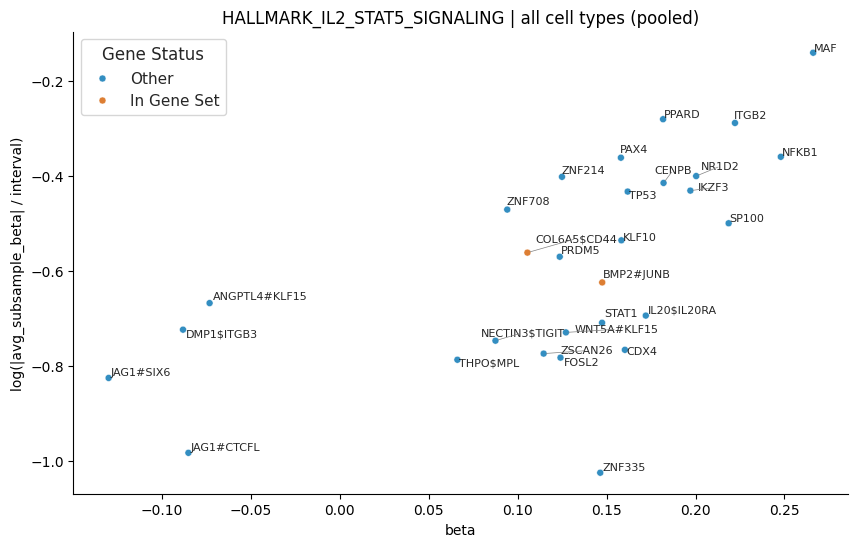

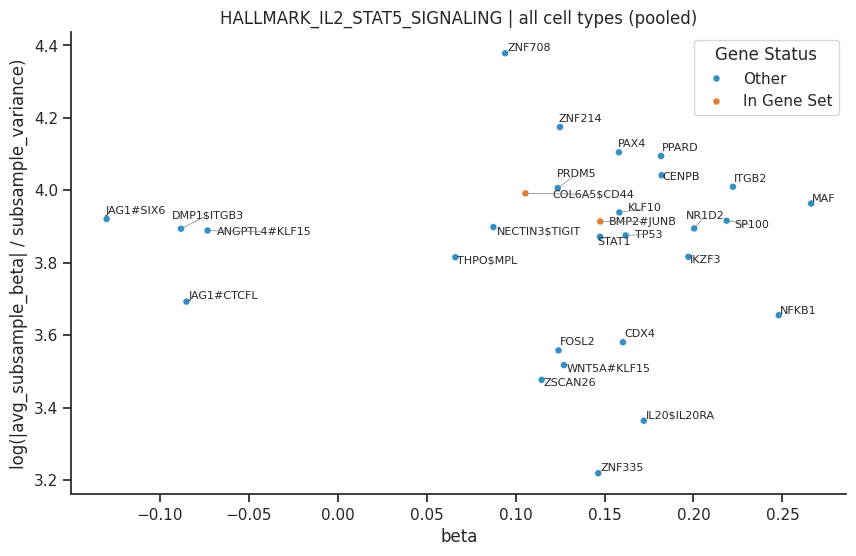

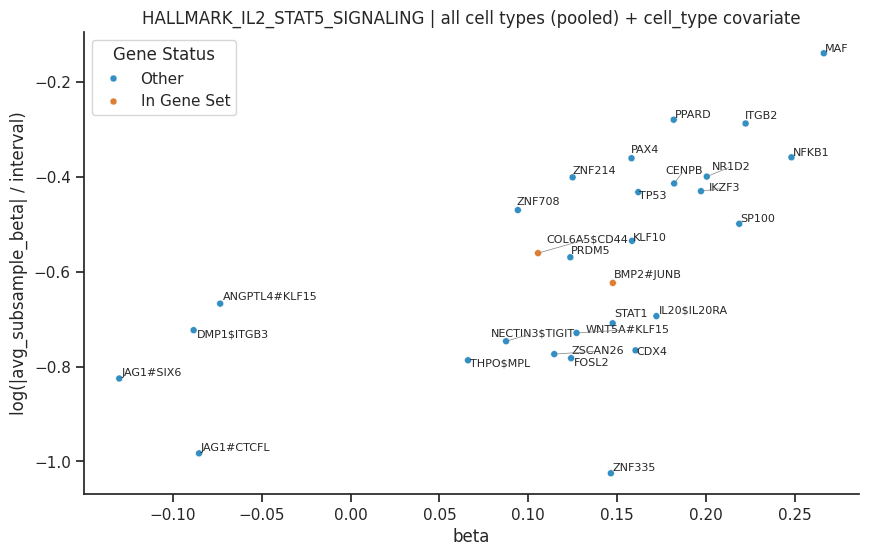

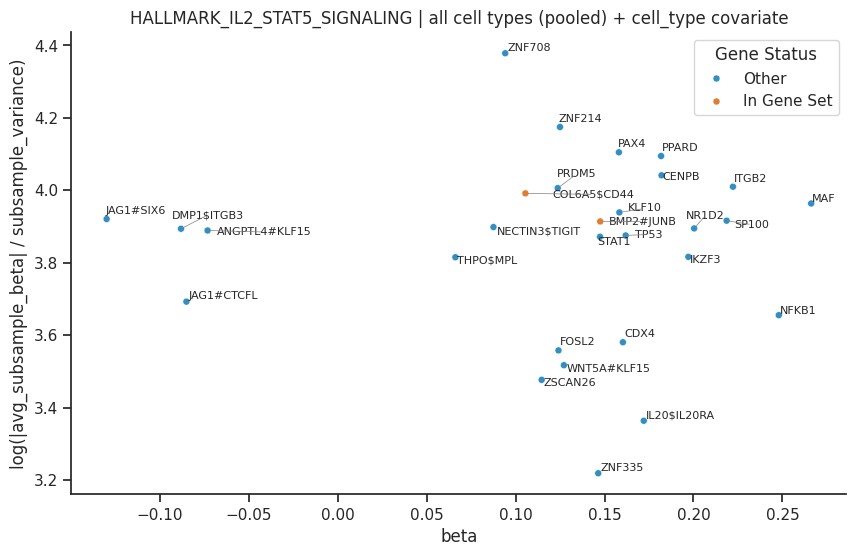

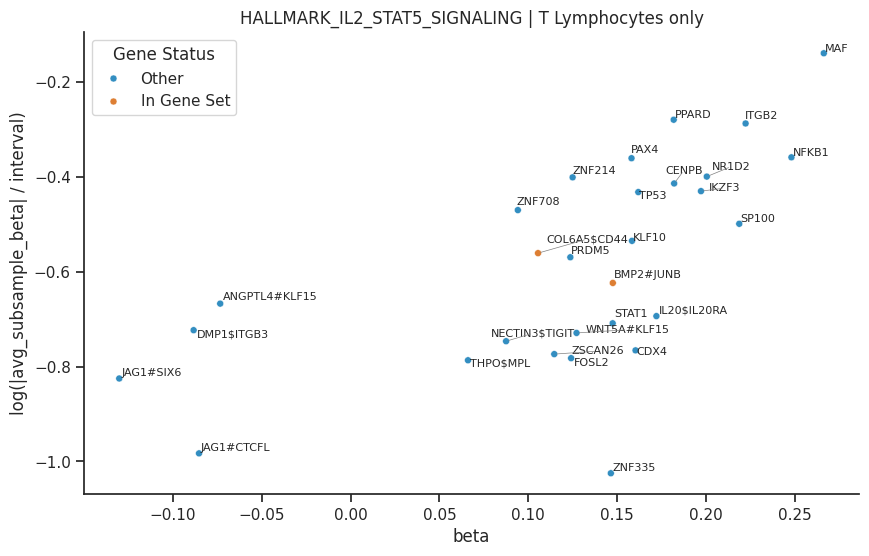

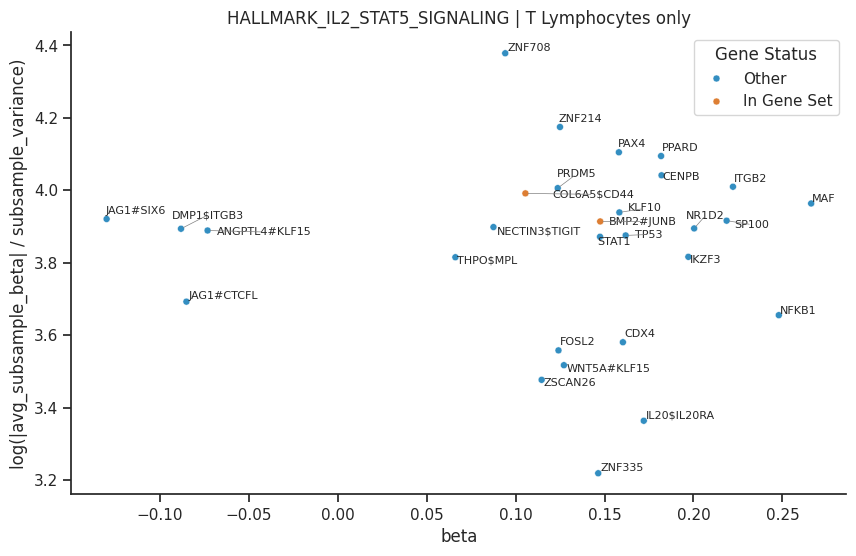

In [7]:
_ = sh.run_signature(adata, 'HALLMARK_IL2_STAT5_SIGNALING', tcell_sets, cell_types=T_CELL_TYPES,
                     cell_type_col=CELL_TYPE_COL, method=METHOD, penalty=PENALTY,
                     standardize=STANDARDIZE, n_sub=N_SUB, lower=LOWER, upper=UPPER)

[add_gene_signature 'KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY'] factor_mode='union' keep_when_overlap='factor'
  dropped 26 gene(s) from the target: ['CD28', 'CD4', 'CD40LG', 'CD8A', 'CD8B', 'CSF2', 'CTLA4', 'FOS', 'ICOS', 'IFNG', 'IL10', 'IL2', 'IL4', 'IL5', 'JUN', 'LCK', 'NFAT5', 'NFATC1', 'NFATC2', 'NFATC3', 'NFATC4', 'NFKB1', 'PDCD1', 'PTPRC', 'RELA', 'TNF']
  kept all 6415 factor(s)

===== KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY | all cell types (pooled) =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
6130,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,ITGB2,tf,0.384128,0.370470,0.137248,0.876945,8018,0.267746,0.523679,0.389972,0.003849,0.003883,0.327938,0.461453,0.353279,0.393780,0.370598
3782,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,EGF#FOSL1,ltf,-0.263803,0.009299,0.000086,0.876945,8018,-0.388746,-0.000000,-0.112120,0.007509,0.030517,-0.190981,-0.001918,-0.007045,0.031038,0.012110
4477,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,RFX3,tf,0.260094,0.102630,0.010533,0.876945,8018,0.000000,0.381610,0.175310,0.007086,0.014274,0.082041,0.252923,0.058324,0.125247,0.102125
2136,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,IL15#E2F1,ltf,-0.252796,0.084137,0.007079,0.876945,8018,-0.299026,-0.000000,-0.046430,0.006602,0.049189,-0.119125,-0.000000,0.066354,0.119012,0.089006
1673,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,LAMB1$SV2A,lr,-0.245791,0.045662,0.002085,0.876945,8018,-0.288680,-0.000000,-0.153798,0.004650,0.013112,-0.218566,-0.091272,0.023203,0.079729,0.047693
5366,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,SP100,tf,0.244430,0.238636,0.056947,0.876945,8018,0.076440,0.330469,0.214743,0.004502,0.005384,0.131472,0.278620,0.216204,0.261791,0.237456
4108,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,ATF6B,tf,0.241400,0.154549,0.023886,0.876945,8018,0.089734,0.307849,0.188151,0.002377,0.005212,0.133744,0.241852,0.124697,0.182190,0.151386
5763,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,TNFSF11#CDC5L,ltf,-0.233998,0.070993,0.005040,0.876945,8018,-0.325891,-0.000000,-0.144065,0.005086,0.013174,-0.226691,-0.071199,0.044709,0.103706,0.071250
1899,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,LCK$CD8A,lr,0.233981,0.287166,0.082465,0.876945,8018,0.129233,0.409870,0.225092,0.004312,0.004391,0.159627,0.288425,0.237478,0.314490,0.284416
5175,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,IRF8,tf,-0.229688,0.049388,0.002439,0.876945,8018,-0.382317,-0.018625,-0.146925,0.005493,0.012343,-0.207332,-0.070591,0.016629,0.083546,0.050093



===== KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY | all cell types (pooled) + cell_type covariate =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
6130,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,ITGB2,tf,0.384128,0.370470,0.137248,0.876945,8018,0.267746,0.523679,0.389972,0.003849,0.003883,0.327938,0.461453,0.353279,0.393780,0.370598
3782,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,EGF#FOSL1,ltf,-0.263803,0.009299,0.000086,0.876945,8018,-0.388746,-0.000000,-0.112120,0.007509,0.030517,-0.190981,-0.001918,-0.007045,0.031038,0.012110
4477,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,RFX3,tf,0.260094,0.102630,0.010533,0.876945,8018,0.000000,0.381610,0.175310,0.007086,0.014274,0.082041,0.252923,0.058324,0.125247,0.102125
2136,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,IL15#E2F1,ltf,-0.252796,0.084137,0.007079,0.876945,8018,-0.299026,-0.000000,-0.046430,0.006602,0.049189,-0.119125,-0.000000,0.066354,0.119012,0.089006
1673,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,LAMB1$SV2A,lr,-0.245791,0.045662,0.002085,0.876945,8018,-0.288680,-0.000000,-0.153798,0.004650,0.013112,-0.218566,-0.091272,0.023203,0.079729,0.047693
5366,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,SP100,tf,0.244430,0.238636,0.056947,0.876945,8018,0.076440,0.330469,0.214743,0.004502,0.005384,0.131472,0.278620,0.216204,0.261791,0.237456
4108,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,ATF6B,tf,0.241400,0.154549,0.023886,0.876945,8018,0.089734,0.307849,0.188151,0.002377,0.005212,0.133744,0.241852,0.124697,0.182190,0.151386
5763,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,TNFSF11#CDC5L,ltf,-0.233998,0.070993,0.005040,0.876945,8018,-0.325891,-0.000000,-0.144065,0.005086,0.013174,-0.226691,-0.071199,0.044709,0.103706,0.071250
1899,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,LCK$CD8A,lr,0.233981,0.287166,0.082465,0.876945,8018,0.129233,0.409870,0.225092,0.004312,0.004391,0.159627,0.288425,0.237478,0.314490,0.284416
5175,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,IRF8,tf,-0.229688,0.049388,0.002439,0.876945,8018,-0.382317,-0.018625,-0.146925,0.005493,0.012343,-0.207332,-0.070591,0.016629,0.083546,0.050093



===== KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY | T Lymphocytes only =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
6130,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,ITGB2,tf,0.384128,0.370470,0.137248,0.876945,8018,0.267746,0.523679,0.389972,0.003849,0.003883,0.327938,0.461453,0.353279,0.393780,0.370598
3782,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,EGF#FOSL1,ltf,-0.263803,0.009299,0.000086,0.876945,8018,-0.388746,-0.000000,-0.112120,0.007509,0.030517,-0.190981,-0.001918,-0.007045,0.031038,0.012110
4477,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,RFX3,tf,0.260094,0.102630,0.010533,0.876945,8018,0.000000,0.381610,0.175310,0.007086,0.014274,0.082041,0.252923,0.058324,0.125247,0.102125
2136,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,IL15#E2F1,ltf,-0.252796,0.084137,0.007079,0.876945,8018,-0.299026,-0.000000,-0.046430,0.006602,0.049189,-0.119125,-0.000000,0.066354,0.119012,0.089006
1673,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,LAMB1$SV2A,lr,-0.245791,0.045662,0.002085,0.876945,8018,-0.288680,-0.000000,-0.153798,0.004650,0.013112,-0.218566,-0.091272,0.023203,0.079729,0.047693
5366,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,SP100,tf,0.244430,0.238636,0.056947,0.876945,8018,0.076440,0.330469,0.214743,0.004502,0.005384,0.131472,0.278620,0.216204,0.261791,0.237456
4108,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,ATF6B,tf,0.241400,0.154549,0.023886,0.876945,8018,0.089734,0.307849,0.188151,0.002377,0.005212,0.133744,0.241852,0.124697,0.182190,0.151386
5763,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,TNFSF11#CDC5L,ltf,-0.233998,0.070993,0.005040,0.876945,8018,-0.325891,-0.000000,-0.144065,0.005086,0.013174,-0.226691,-0.071199,0.044709,0.103706,0.071250
1899,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,LCK$CD8A,lr,0.233981,0.287166,0.082465,0.876945,8018,0.129233,0.409870,0.225092,0.004312,0.004391,0.159627,0.288425,0.237478,0.314490,0.284416
5175,KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY,IRF8,tf,-0.229688,0.049388,0.002439,0.876945,8018,-0.382317,-0.018625,-0.146925,0.005493,0.012343,-0.207332,-0.070591,0.016629,0.083546,0.050093


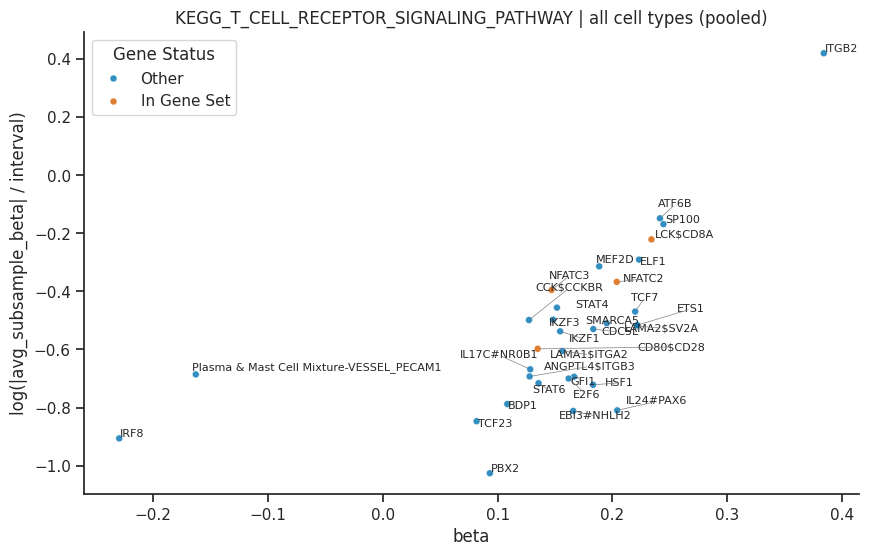

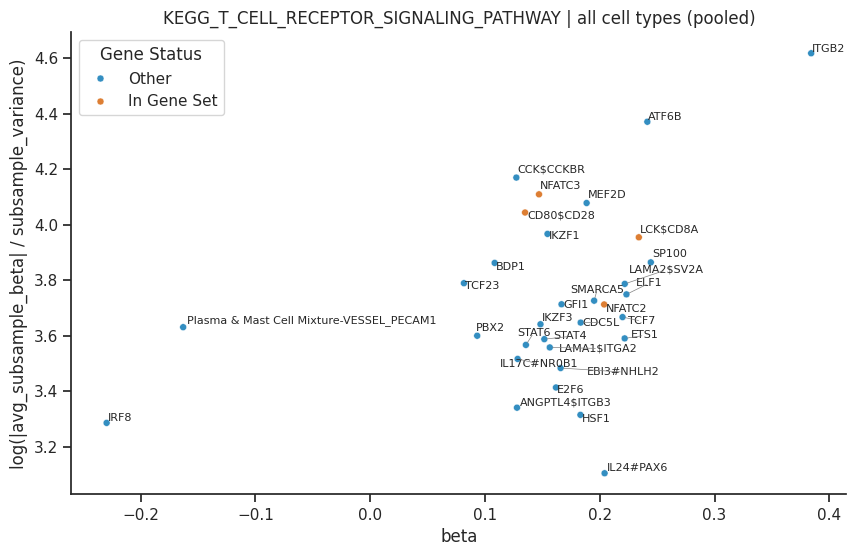

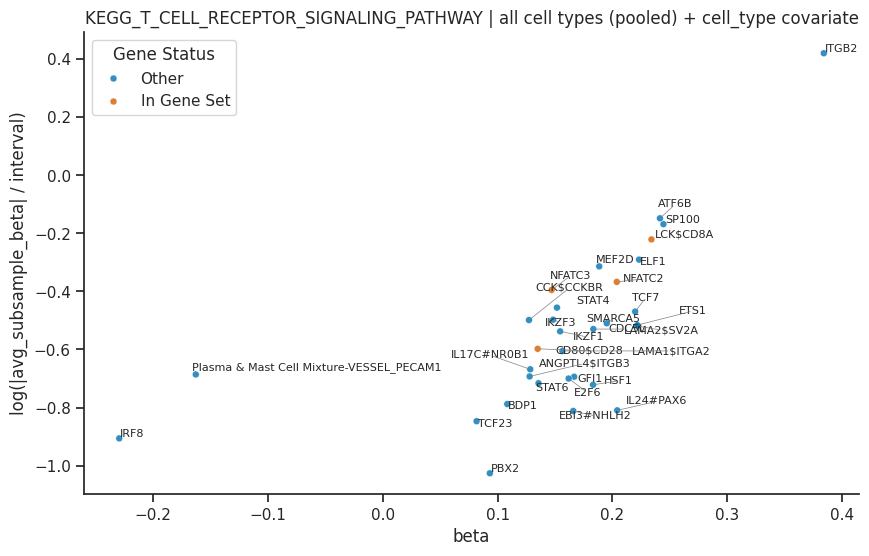

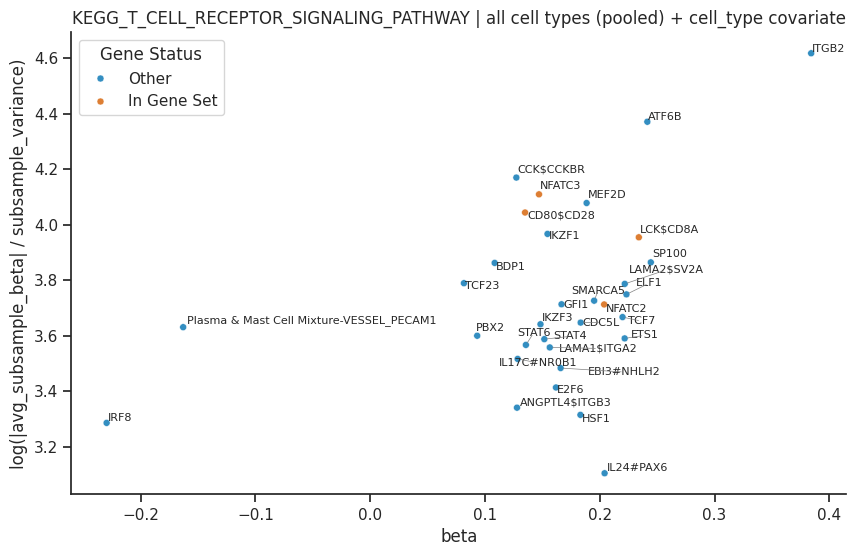

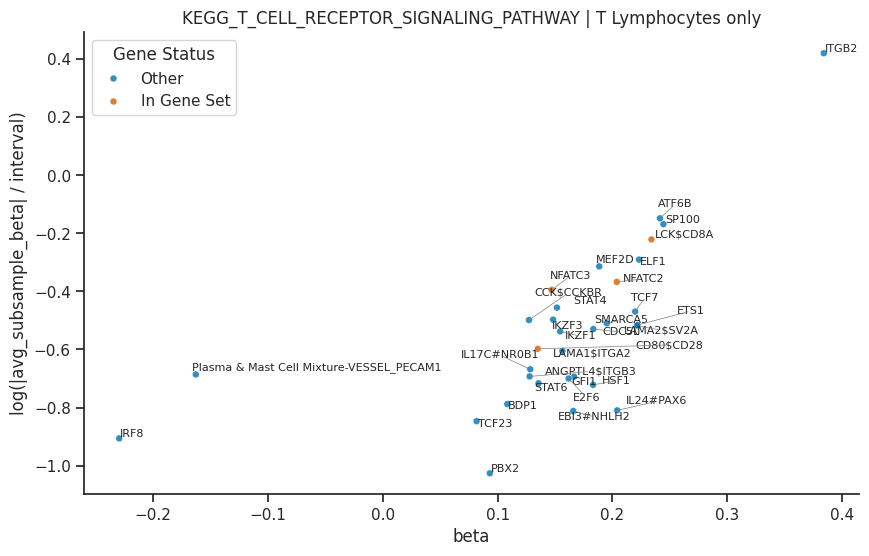

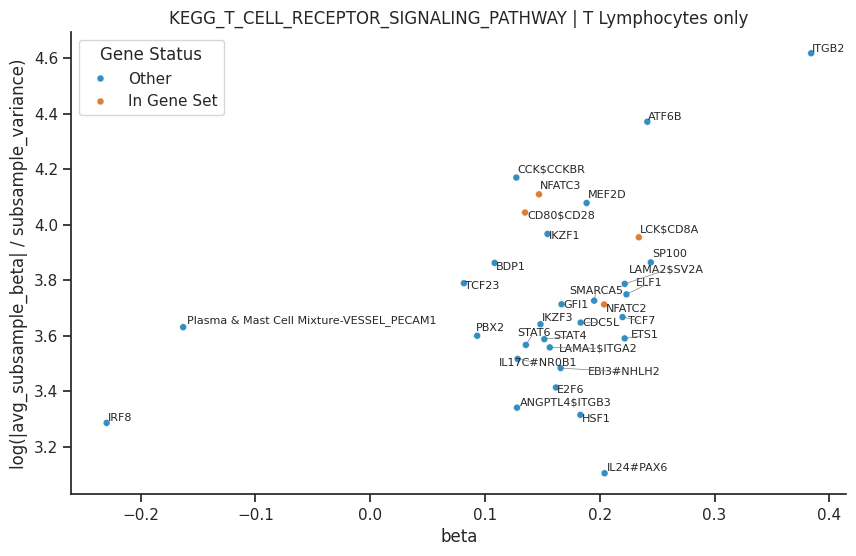

In [8]:
_ = sh.run_signature(adata, 'KEGG_T_CELL_RECEPTOR_SIGNALING_PATHWAY', tcell_sets, cell_types=T_CELL_TYPES,
                     cell_type_col=CELL_TYPE_COL, method=METHOD, penalty=PENALTY,
                     standardize=STANDARDIZE, n_sub=N_SUB, lower=LOWER, upper=UPPER)

[add_gene_signature 'GOBP_T_CELL_MEDIATED_CYTOTOXICITY'] factor_mode='union' keep_when_overlap='factor'
  dropped 27 gene(s) from the target: ['CADM1', 'CD1D', 'CEACAM1', 'HLA-A', 'HLA-B', 'HLA-C', 'HLA-DRA', 'HLA-DRB1', 'HLA-E', 'HLA-F', 'HLA-G', 'IL12A', 'IL12B', 'IL12RB1', 'IL23A', 'IL23R', 'IL7R', 'KLRC1', 'KLRD1', 'LILRB1', 'NECTIN2', 'PTPRC', 'PVR', 'RAET1E', 'RAET1G', 'ULBP1', 'XCL1']
  kept all 6242 factor(s)

===== GOBP_T_CELL_MEDIATED_CYTOTOXICITY | all cell types (pooled) =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
5809,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,ITGB2,tf,0.174730,0.319098,0.101824,0.719551,8018,0.092288,0.232032,0.173694,0.000814,0.000815,0.143261,0.198611,0.289534,0.350137,0.320179
13,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,ETS1,tf,0.114846,0.233989,0.054751,0.719551,8018,0.052050,0.177314,0.114923,0.000751,0.000751,0.087382,0.146504,0.216344,0.254775,0.233366
2411,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,IKZF1,tf,0.104013,0.213414,0.045545,0.719551,8018,0.009689,0.143090,0.090762,0.000898,0.001073,0.063066,0.118186,0.197756,0.231303,0.214607
606,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,MIF$CD74,lr,0.098644,0.198187,0.039278,0.719551,8018,0.026164,0.130997,0.082070,0.000541,0.000816,0.056185,0.104715,0.163623,0.243960,0.196985
3965,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,FOXM1,tf,0.094465,0.138718,0.019243,0.719551,8018,0.013233,0.171811,0.092960,0.001080,0.001082,0.062563,0.123324,0.101645,0.166565,0.138231
6460,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,CXCL14+ Fibroblasts-HALLMARK_HYPOXIA,custom,0.090129,-0.030401,0.000924,0.719551,8018,0.000000,0.200762,0.052409,0.001906,0.003329,0.003204,0.082790,-0.049836,0.008529,-0.031503
261,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,WNT3$LRP5,lr,0.087338,0.043091,0.001857,0.719551,8018,0.000000,0.148575,0.051271,0.001535,0.002836,0.006449,0.093816,0.016478,0.066759,0.043296
1185,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,COL6A3$ITGA2,lr,0.087136,0.073158,0.005352,0.719551,8018,0.000000,0.124815,0.055333,0.000637,0.001648,0.028600,0.079143,0.045640,0.109243,0.076491
5572,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,SP100,tf,0.084013,0.220317,0.048540,0.719551,8018,0.033344,0.161095,0.077275,0.000513,0.000559,0.053312,0.096004,0.192516,0.249686,0.218578
458,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,FGF9$FGFR2,lr,0.083924,0.047352,0.002242,0.719551,8018,0.000000,0.103380,0.042643,0.000970,0.002674,0.001835,0.077507,0.017822,0.082087,0.044672



===== GOBP_T_CELL_MEDIATED_CYTOTOXICITY | all cell types (pooled) + cell_type covariate =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
5809,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,ITGB2,tf,0.174730,0.319098,0.101824,0.719551,8018,0.092288,0.232032,0.173694,0.000814,0.000815,0.143261,0.198611,0.289534,0.350137,0.320179
13,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,ETS1,tf,0.114846,0.233989,0.054751,0.719551,8018,0.052050,0.177314,0.114923,0.000751,0.000751,0.087382,0.146504,0.216344,0.254775,0.233366
2411,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,IKZF1,tf,0.104013,0.213414,0.045545,0.719551,8018,0.009689,0.143090,0.090762,0.000898,0.001073,0.063066,0.118186,0.197756,0.231303,0.214607
606,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,MIF$CD74,lr,0.098644,0.198187,0.039278,0.719551,8018,0.026164,0.130997,0.082070,0.000541,0.000816,0.056185,0.104715,0.163623,0.243960,0.196985
3965,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,FOXM1,tf,0.094465,0.138718,0.019243,0.719551,8018,0.013233,0.171811,0.092960,0.001080,0.001082,0.062563,0.123324,0.101645,0.166565,0.138231
6460,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,CXCL14+ Fibroblasts-HALLMARK_HYPOXIA,custom,0.090129,-0.030401,0.000924,0.719551,8018,0.000000,0.200762,0.052409,0.001906,0.003329,0.003204,0.082790,-0.049836,0.008529,-0.031503
261,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,WNT3$LRP5,lr,0.087338,0.043091,0.001857,0.719551,8018,0.000000,0.148575,0.051271,0.001535,0.002836,0.006449,0.093816,0.016478,0.066759,0.043296
1185,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,COL6A3$ITGA2,lr,0.087136,0.073158,0.005352,0.719551,8018,0.000000,0.124815,0.055333,0.000637,0.001648,0.028600,0.079143,0.045640,0.109243,0.076491
5572,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,SP100,tf,0.084013,0.220317,0.048540,0.719551,8018,0.033344,0.161095,0.077275,0.000513,0.000559,0.053312,0.096004,0.192516,0.249686,0.218578
458,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,FGF9$FGFR2,lr,0.083924,0.047352,0.002242,0.719551,8018,0.000000,0.103380,0.042643,0.000970,0.002674,0.001835,0.077507,0.017822,0.082087,0.044672



===== GOBP_T_CELL_MEDIATED_CYTOTOXICITY | T Lymphocytes only =====


,gene,factor,group,beta,r,r2,model_r2,n_cells,min_subsample_beta,max_subsample_beta,avg_subsample_beta,var_subsample_beta,msd_subsample_beta,lower_15_subsample_beta,upper_85_subsample_beta,min_subsample_r,max_subsample_r,avg_subsample_r
5809,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,ITGB2,tf,0.174730,0.319098,0.101824,0.719551,8018,0.092288,0.232032,0.173694,0.000814,0.000815,0.143261,0.198611,0.289534,0.350137,0.320179
13,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,ETS1,tf,0.114846,0.233989,0.054751,0.719551,8018,0.052050,0.177314,0.114923,0.000751,0.000751,0.087382,0.146504,0.216344,0.254775,0.233366
2411,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,IKZF1,tf,0.104013,0.213414,0.045545,0.719551,8018,0.009689,0.143090,0.090762,0.000898,0.001073,0.063066,0.118186,0.197756,0.231303,0.214607
606,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,MIF$CD74,lr,0.098644,0.198187,0.039278,0.719551,8018,0.026164,0.130997,0.082070,0.000541,0.000816,0.056185,0.104715,0.163623,0.243960,0.196985
3965,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,FOXM1,tf,0.094465,0.138718,0.019243,0.719551,8018,0.013233,0.171811,0.092960,0.001080,0.001082,0.062563,0.123324,0.101645,0.166565,0.138231
6460,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,CXCL14+ Fibroblasts-HALLMARK_HYPOXIA,custom,0.090129,-0.030401,0.000924,0.719551,8018,0.000000,0.200762,0.052409,0.001906,0.003329,0.003204,0.082790,-0.049836,0.008529,-0.031503
261,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,WNT3$LRP5,lr,0.087338,0.043091,0.001857,0.719551,8018,0.000000,0.148575,0.051271,0.001535,0.002836,0.006449,0.093816,0.016478,0.066759,0.043296
1185,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,COL6A3$ITGA2,lr,0.087136,0.073158,0.005352,0.719551,8018,0.000000,0.124815,0.055333,0.000637,0.001648,0.028600,0.079143,0.045640,0.109243,0.076491
5572,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,SP100,tf,0.084013,0.220317,0.048540,0.719551,8018,0.033344,0.161095,0.077275,0.000513,0.000559,0.053312,0.096004,0.192516,0.249686,0.218578
458,GOBP_T_CELL_MEDIATED_CYTOTOXICITY,FGF9$FGFR2,lr,0.083924,0.047352,0.002242,0.719551,8018,0.000000,0.103380,0.042643,0.000970,0.002674,0.001835,0.077507,0.017822,0.082087,0.044672


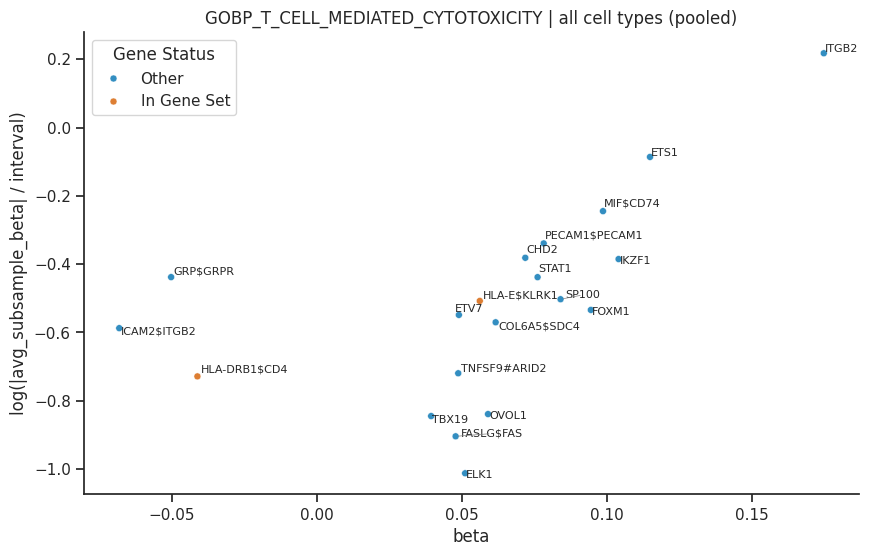

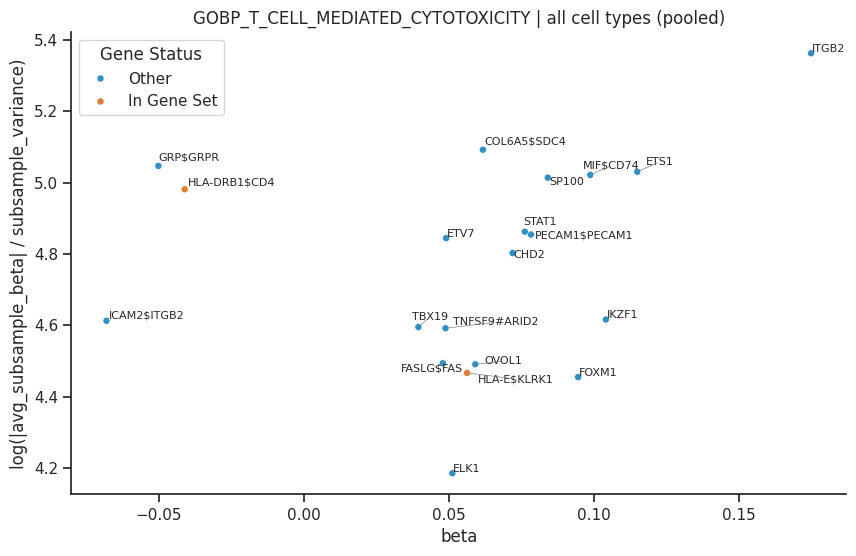

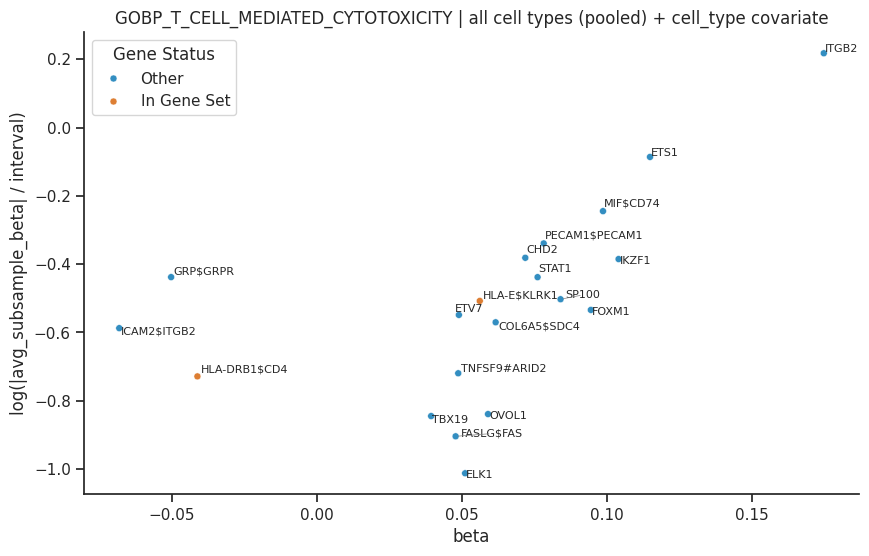

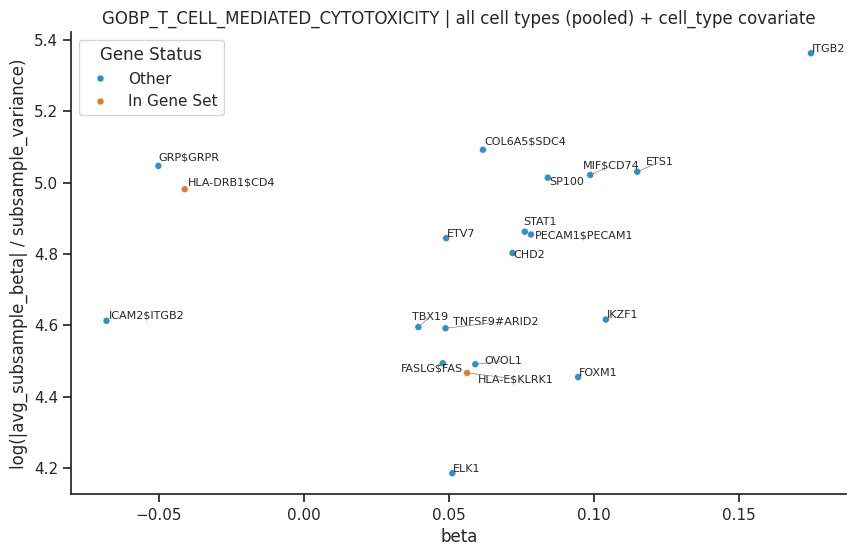

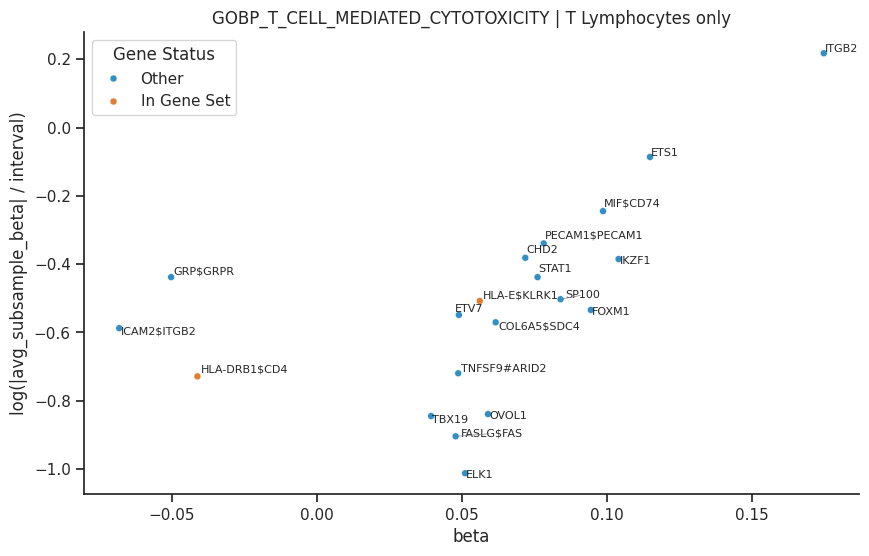

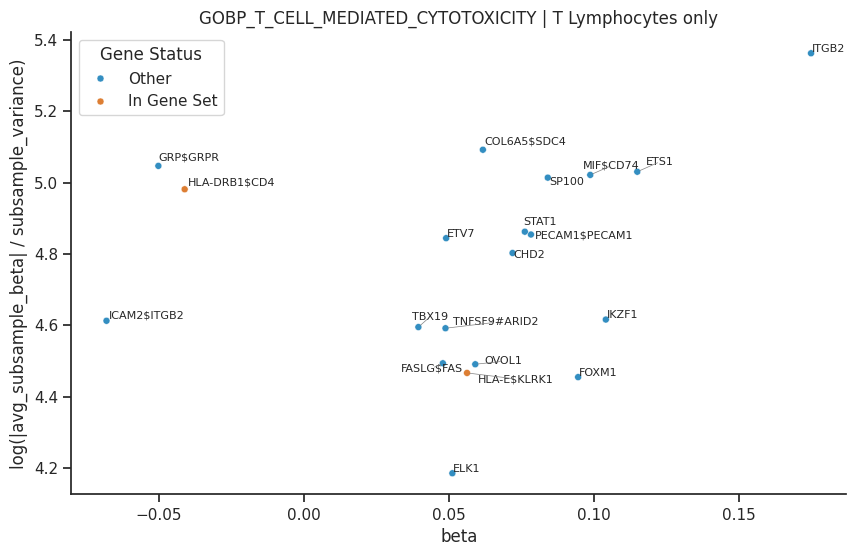

In [9]:
_ = sh.run_signature(adata, 'GOBP_T_CELL_MEDIATED_CYTOTOXICITY', tcell_sets, cell_types=T_CELL_TYPES,
                     cell_type_col=CELL_TYPE_COL, method=METHOD, penalty=PENALTY,
                     standardize=STANDARDIZE, n_sub=N_SUB, lower=LOWER, upper=UPPER)

In [ ]:
_ = sh.run_signature(adata, 'KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY', tcell_sets, cell_types=T_CELL_TYPES,
                     cell_type_col=CELL_TYPE_COL, method=METHOD, penalty=PENALTY,
                     standardize=STANDARDIZE, n_sub=N_SUB, lower=LOWER, upper=UPPER)

[add_gene_signature 'KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY'] factor_mode='union' keep_when_overlap='factor'
  dropped 57 gene(s) from the target: ['CD244', 'CD48', 'CSF2', 'FAS', 'FASLG', 'HCST', 'HLA-A', 'HLA-B', 'HLA-C', 'HLA-E', 'HLA-G', 'ICAM1', 'ICAM2', 'IFNA1', 'IFNA10', 'IFNA13', 'IFNA14', 'IFNA16', 'IFNA17', 'IFNA2', 'IFNA21', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7', 'IFNA8', 'IFNAR1', 'IFNAR2', 'IFNB1', 'IFNG', 'IFNGR1', 'IFNGR2', 'ITGAL', 'ITGB2', 'KIR2DL1', 'KIR2DL3', 'KIR3DL1', 'KIR3DL2', 'KLRC1', 'KLRC2', 'KLRC3', 'KLRD1', 'KLRK1', 'LCK', 'NCR3', 'NFAT5', 'NFATC1', 'NFATC2', 'NFATC3', 'NFATC4', 'RAET1E', 'RAET1G', 'TNF', 'TNFRSF10A', 'TNFSF10', 'TYROBP', 'ULBP1']
  kept all 6438 factor(s)

===== KEGG_NATURAL_KILLER_CELL_MEDIATED_CYTOTOXICITY | all cell types (pooled) =====


In [ ]:
_ = sh.run_signature(adata, 'HALLMARK_TNFA_SIGNALING_VIA_NFKB', tcell_sets, cell_types=T_CELL_TYPES,
                     cell_type_col=CELL_TYPE_COL, method=METHOD, penalty=PENALTY,
                     standardize=STANDARDIZE, n_sub=N_SUB, lower=LOWER, upper=UPPER)

In [ ]:
_ = sh.run_signature(adata, 'HALLMARK_INTERFERON_GAMMA_RESPONSE', tcell_sets, cell_types=T_CELL_TYPES,
                     cell_type_col=CELL_TYPE_COL, method=METHOD, penalty=PENALTY,
                     standardize=STANDARDIZE, n_sub=N_SUB, lower=LOWER, upper=UPPER)

In [ ]:
_ = sh.run_signature(adata, 'HALLMARK_INTERFERON_ALPHA_RESPONSE', tcell_sets, cell_types=T_CELL_TYPES,
                     cell_type_col=CELL_TYPE_COL, method=METHOD, penalty=PENALTY,
                     standardize=STANDARDIZE, n_sub=N_SUB, lower=LOWER, upper=UPPER)

In [ ]:
_ = sh.run_signature(adata, 'GOBP_CELL_KILLING', tcell_sets, cell_types=T_CELL_TYPES,
                     cell_type_col=CELL_TYPE_COL, method=METHOD, penalty=PENALTY,
                     standardize=STANDARDIZE, n_sub=N_SUB, lower=LOWER, upper=UPPER)

In [ ]:
_ = sh.run_signature(adata, 'GOBP_GRANZYME_MEDIATED_PROGRAMMED_CELL_DEATH_SIGNALING_PATHWAY', tcell_sets, cell_types=T_CELL_TYPES,
                     cell_type_col=CELL_TYPE_COL, method=METHOD, penalty=PENALTY,
                     standardize=STANDARDIZE, n_sub=N_SUB, lower=LOWER, upper=UPPER)

In [ ]:
_ = sh.run_signature(adata, 'GOBP_LYMPHOCYTE_MEDIATED_IMMUNITY', tcell_sets, cell_types=T_CELL_TYPES,
                     cell_type_col=CELL_TYPE_COL, method=METHOD, penalty=PENALTY,
                     standardize=STANDARDIZE, n_sub=N_SUB, lower=LOWER, upper=UPPER)

## Negative controls

In [ ]:
_ = sh.run_signature(adata, 'HALLMARK_PANCREAS_BETA_CELLS', tcell_sets, cell_types=T_CELL_TYPES,
                     cell_type_col=CELL_TYPE_COL, method=METHOD, penalty=PENALTY,
                     standardize=STANDARDIZE, n_sub=N_SUB, lower=LOWER, upper=UPPER)

In [ ]:
_ = sh.run_signature(adata, 'HALLMARK_SPERMATOGENESIS', tcell_sets, cell_types=T_CELL_TYPES,
                     cell_type_col=CELL_TYPE_COL, method=METHOD, penalty=PENALTY,
                     standardize=STANDARDIZE, n_sub=N_SUB, lower=LOWER, upper=UPPER)